In [1]:
import cv2, glob, os, zipfile, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from skimage.morphology import reconstruction

DOCX = "OPE_6.docx"
os.makedirs("dataset", exist_ok=True)
if os.path.exists(DOCX):
    with zipfile.ZipFile(DOCX) as z:
        for n in z.namelist():
            if n.startswith("word/media/"):
                open("dataset/" + os.path.basename(n), "wb").write(z.read(n))
paths = sorted(glob.glob("dataset/*"))
print(len(paths), [os.path.basename(p) for p in paths])

3 ['image1.png', 'image2.jpeg', 'image3.png']


In [2]:
PARAMS = {"image1": (31, 5), "image2": (5, 5), "image3": (5, 3)}

def se(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def open_rec(b, k):
    return reconstruction(cv2.erode(b, se(k)), b, method="dilation").astype(np.uint8)

def close_(b, k):
    return cv2.morphologyEx(b, cv2.MORPH_CLOSE, se(k))

def open_(b, k):
    return cv2.morphologyEx(b, cv2.MORPH_OPEN, se(k))

def ncomp(x):
    return cv2.connectedComponents(x)[0] - 1

def iou(x, y):
    return ((x > 0) & (y > 0)).sum() / ((x > 0) | (y > 0)).sum()

def diff_map(b, f):
    d = np.zeros(b.shape + (3,), np.uint8)
    d[(b > 0) & (f > 0)] = (255, 255, 255)
    d[(b > 0) & (f == 0)] = (255, 0, 0)
    d[(b == 0) & (f > 0)] = (0, 200, 0)
    return d

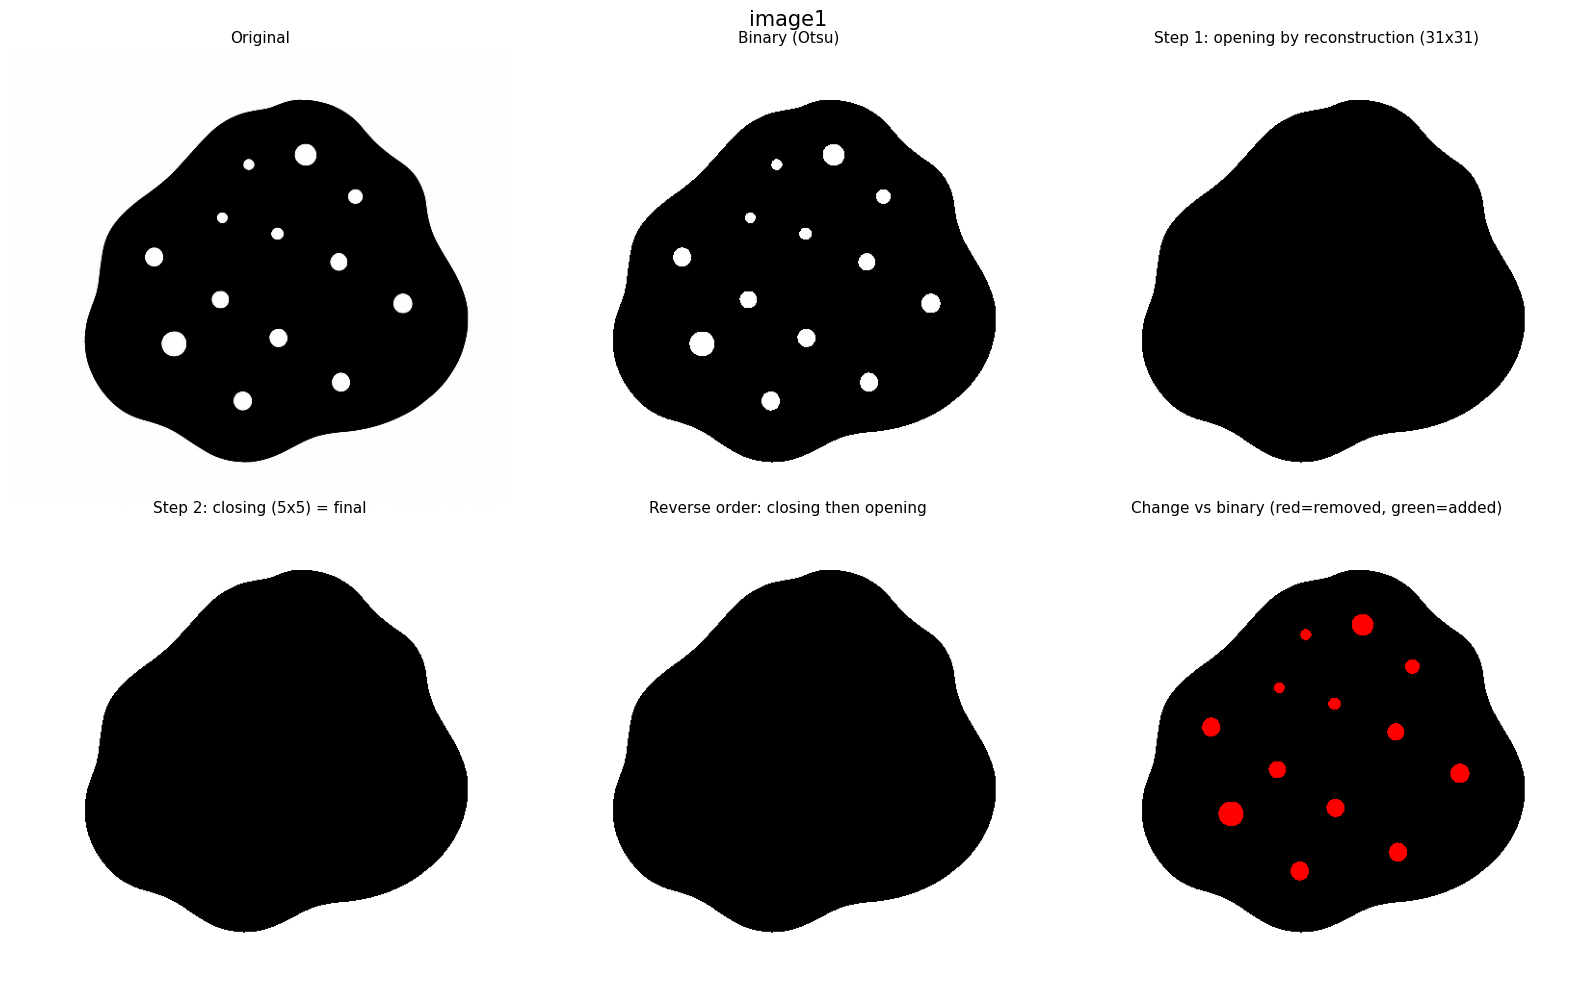

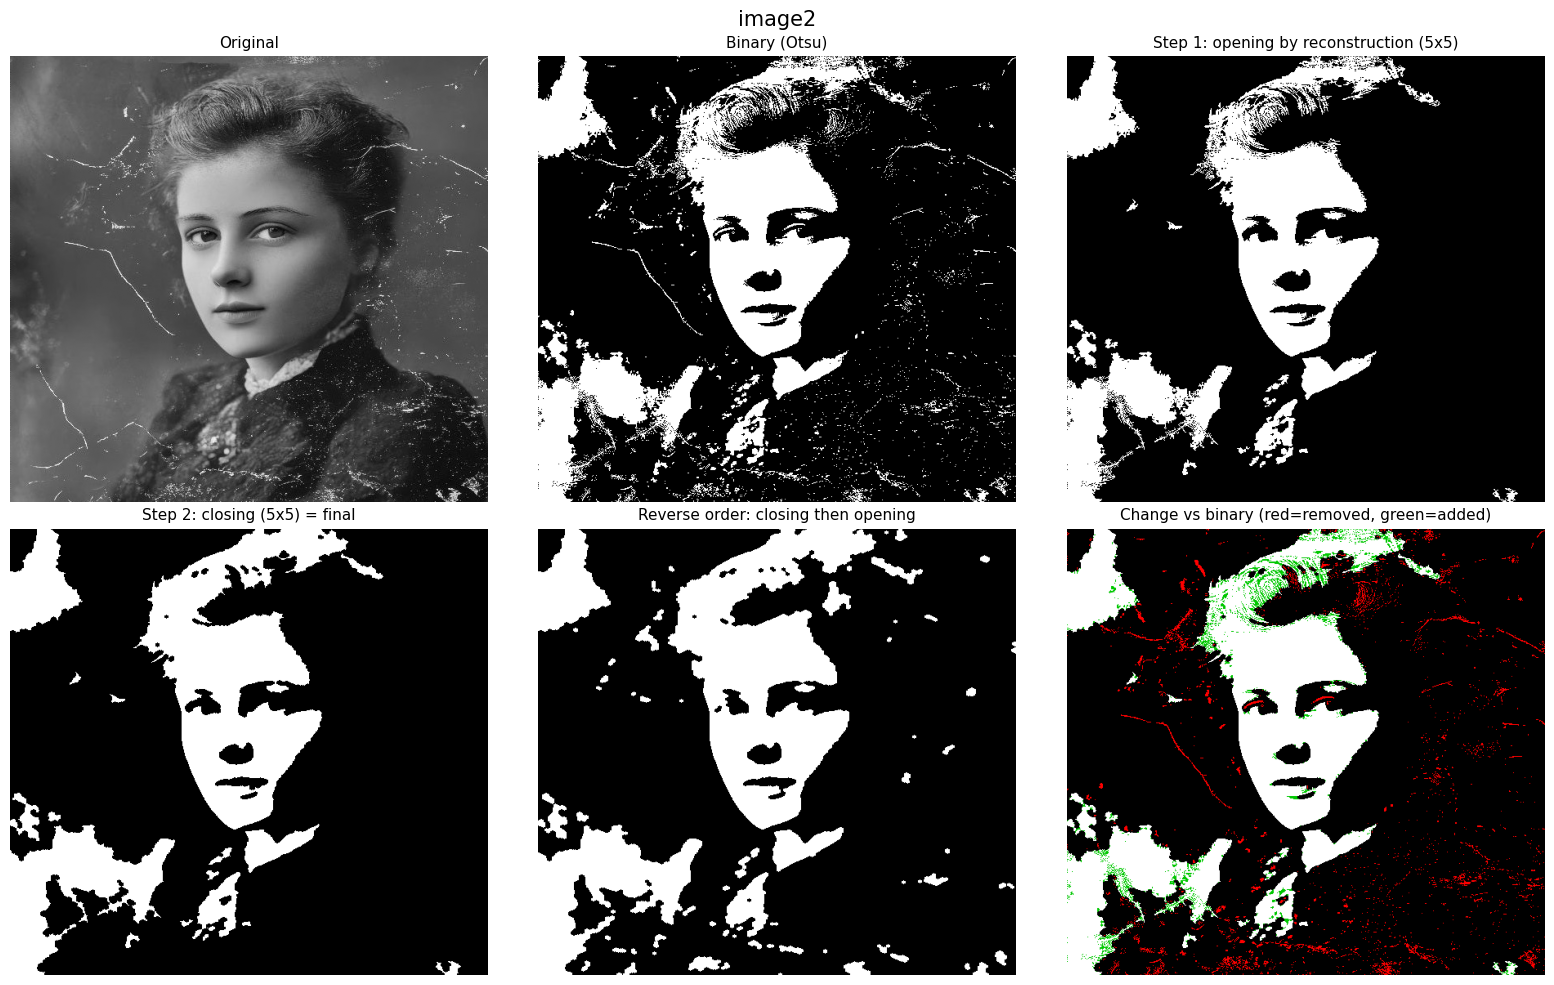

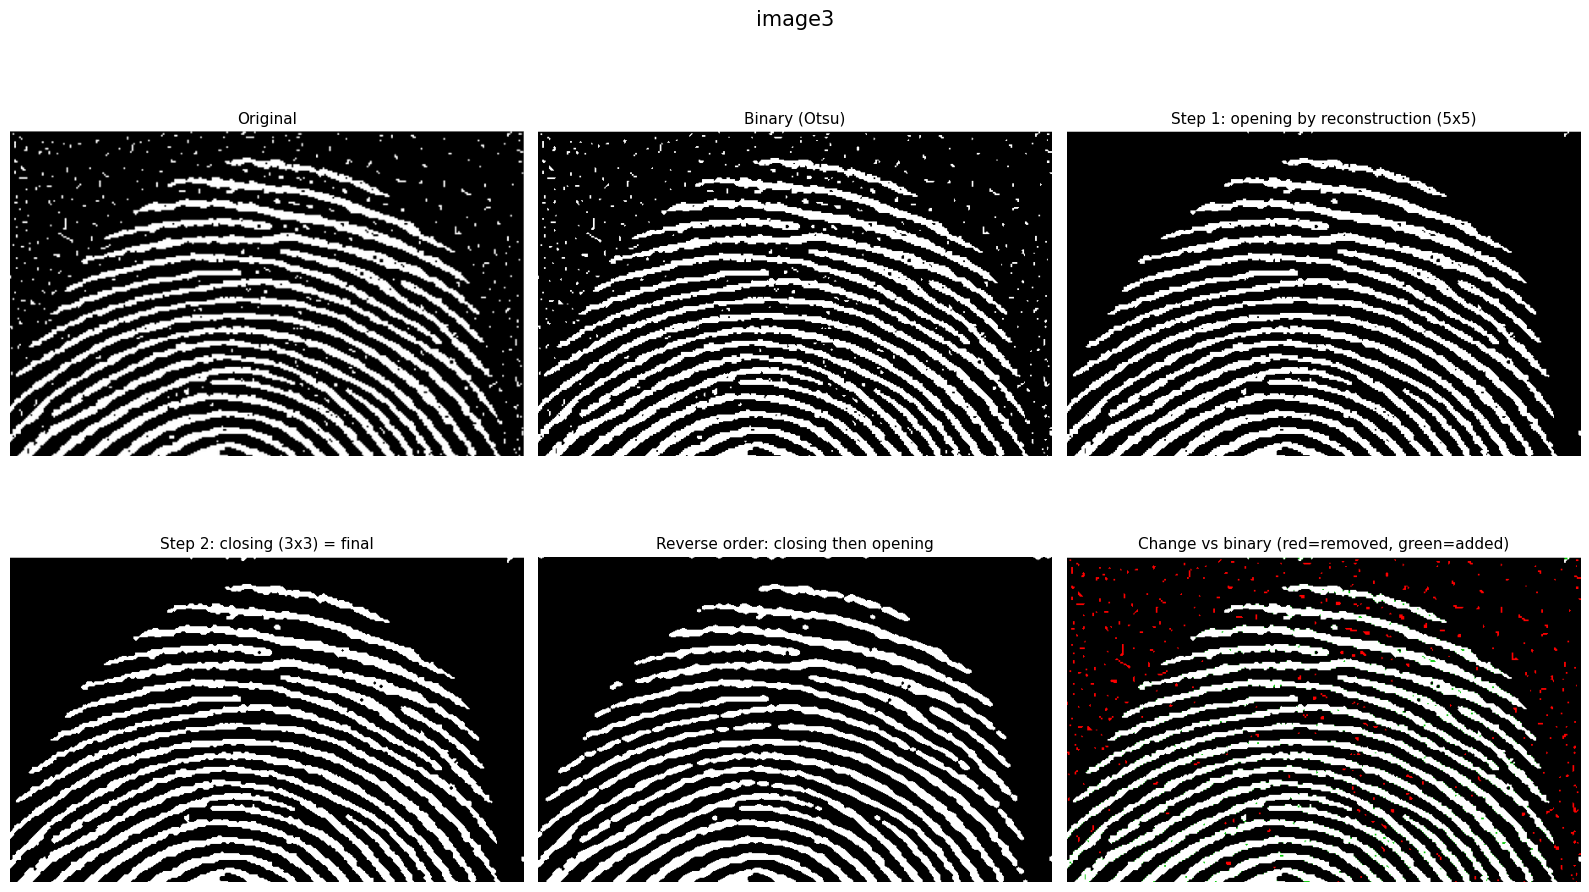

In [ ]:
rows = []
for p in paths:
    g = cv2.imread(p, 0)
    if g is None:
        continue
    name = os.path.splitext(os.path.basename(p))[0]
    ko, kc = PARAMS.get(name, (5, 5))
    _, b = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    step1 = open_rec(b, ko)
    final = close_(step1, kc)
    reverse = open_(close_(b, kc), ko)
    only_open = open_(b, ko)
    only_close = close_(b, kc)
    variants = {"Binary input": b, "Opening only": only_open, "Closing only": only_close,
                "Closing then opening": reverse, "Opening-rec then closing (final)": final}
    for k, v in variants.items():
        rows.append((name, k, ncomp(v), round(iou(b, v), 3), round(100 * ((v > 0).sum() - (b > 0).sum()) / (b > 0).sum(), 2)))
    panels = [("Original", g), ("Binary (Otsu)", b), (f"Step 1: opening by reconstruction ({ko}x{ko})", step1),
              (f"Step 2: closing ({kc}x{kc}) = final", final), ("Reverse order: closing then opening", reverse),
              ("Change vs binary (red=removed, green=added)", diff_map(b, final))]
    fig, ax = plt.subplots(2, 3, figsize=(16, 10))
    for a, (t, x) in zip(ax.ravel(), panels):
        a.imshow(x, cmap="gray", vmin=0, vmax=255) if x.ndim == 2 else a.imshow(x)
        a.set_title(t, fontsize=11)
        a.axis("off")
    fig.suptitle(name, fontsize=15)
    plt.tight_layout()
    plt.show()
    os.makedirs("results", exist_ok=True)
    cv2.imwrite(f"results/{name}_binary.png", b)
    cv2.imwrite(f"results/{name}_final.png", final)

,Image,Operation,Components,IoU with binary input,Area change %
0,image1,Binary input,14,1.000,0.00
1,image1,Opening only,1,0.976,-2.42
2,image1,Closing only,14,1.000,0.00
3,image1,Closing then opening,1,0.976,-2.42
4,image1,Opening-rec then closing (final),1,0.976,-2.42
5,image2,Binary input,1946,1.000,0.00
6,image2,Opening only,52,0.783,-21.72
7,image2,Closing only,965,0.853,17.24
8,image2,Closing then opening,72,0.808,7.05
9,image2,Opening-rec then closing (final),19,0.832,-2.44


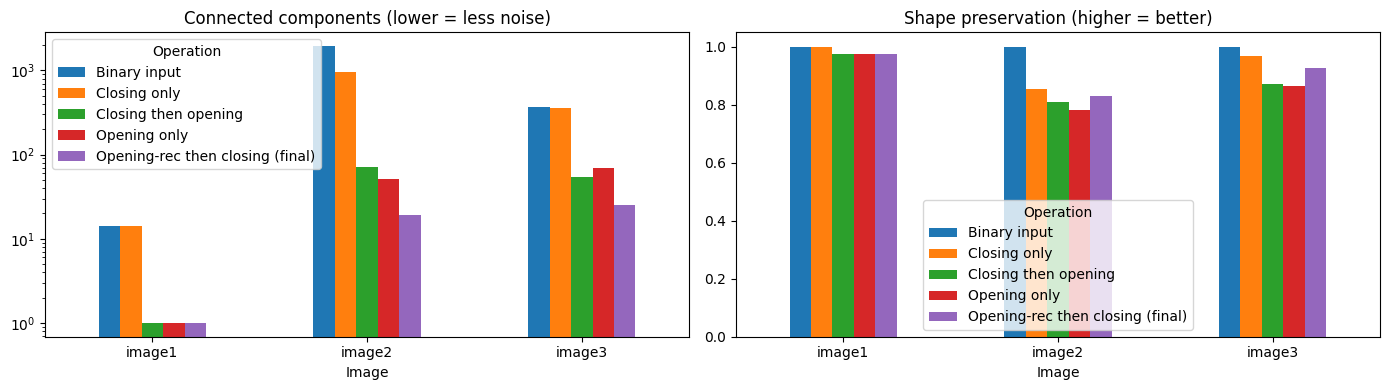

In [4]:
df = pd.DataFrame(rows, columns=["Image", "Operation", "Components", "IoU with binary input", "Area change %"])
df.to_csv("results/metrics.csv", index=False)
display(df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.pivot(index="Image", columns="Operation", values="Components").plot(kind="bar", ax=ax[0], rot=0, logy=True)
df.pivot(index="Image", columns="Operation", values="IoU with binary input").plot(kind="bar", ax=ax[1], rot=0)
ax[0].set_title("Connected components (lower = less noise)")
ax[1].set_title("Shape preservation (higher = better)")
plt.tight_layout()
plt.show()